In [16]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
df = pd.read_csv('../data/raw/AmesHousing.csv')
df.head()

,Order,PID,MS SubClass,MS Zoning,Lot Frontage,Lot Area,Street,Alley,Lot Shape,Land Contour,...,Pool Area,Pool QC,Fence,Misc Feature,Misc Val,Mo Sold,Yr Sold,Sale Type,Sale Condition,SalePrice
0,1,526301100,20,RL,141.0,31770,Pave,NaN,IR1,Lvl,...,0,NaN,NaN,NaN,0,5,2010,WD,Normal,215000
1,2,526350040,20,RH,80.0,11622,Pave,NaN,Reg,Lvl,...,0,NaN,MnPrv,NaN,0,6,2010,WD,Normal,105000
2,3,526351010,20,RL,81.0,14267,Pave,NaN,IR1,Lvl,...,0,NaN,NaN,Gar2,12500,6,2010,WD,Normal,172000
3,4,526353030,20,RL,93.0,11160,Pave,NaN,Reg,Lvl,...,0,NaN,NaN,NaN,0,4,2010,WD,Normal,244000
4,5,527105010,60,RL,74.0,13830,Pave,NaN,IR1,Lvl,...,0,NaN,MnPrv,NaN,0,3,2010,WD,Normal,189900


In [3]:
df.shape

(2930, 82)

There are 2930 rows and 82 columns. Each row represents residential homes in Ames. The target column is the `SalePrice` column

In [4]:
df.duplicated().sum()

np.int64(0)

There are no duplicated records

In [5]:
df.duplicated(subset=['PID']).sum()

np.int64(0)

There are no duplicate identifiers

In [6]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 2930 entries, 0 to 2929
Data columns (total 82 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   Order            2930 non-null   int64  
 1   PID              2930 non-null   int64  
 2   MS SubClass      2930 non-null   int64  
 3   MS Zoning        2930 non-null   str    
 4   Lot Frontage     2440 non-null   float64
 5   Lot Area         2930 non-null   int64  
 6   Street           2930 non-null   str    
 7   Alley            198 non-null    str    
 8   Lot Shape        2930 non-null   str    
 9   Land Contour     2930 non-null   str    
 10  Utilities        2930 non-null   str    
 11  Lot Config       2930 non-null   str    
 12  Land Slope       2930 non-null   str    
 13  Neighborhood     2930 non-null   str    
 14  Condition 1      2930 non-null   str    
 15  Condition 2      2930 non-null   str    
 16  Bldg Type        2930 non-null   str    
 17  House Style      2930 non

Numerical Columns        
1. Yr Sold: Year sold (2006–2010)
2. Lot Frontage
3. Lot Area
4. Year Built
5. Year Remod/Add
6. Mas Vnr Area
7. BsmtFin SF 1
8. BsmtFin SF 2
9. Bsmt Unf SF
10. Total Bsmt SF
11. Bsmt Full Bath ?
12. Bsmt Half Bath ?
13. 1st Flr SF
14. 2nd Flr SF
15. Low Qual Fin SF
16. Gr Liv Area
17. TotRms AbvGrd
18. Full Bath
19. Half Bath
20. Bedroom AbvGr
21. Kitchen AbvGr
22. Fireplaces
23. Garage Yr Blt
24. Garage Cars
25. Garage Area
26. Wood Deck SF
27. Open Porch SF
28. Enclosed Porch
29. 3Ssn Porch
30. Screen Porch
31. Pool Area
32. Misc Val

Categorical Data
1. Mo Sold - Month sold (1 = January, 12 = December) - Convert to Category
2. Sale Type: Type of sale (e.g., WD = Warranty Deed (Conventional), New = New home, CWD = Cash, Oth = Other)
3. Sale Condition
4. MS Zoning
5. Street
6. Alley
7. Lot Shape
8. Land Contour
9. Utilities
10. Lot Config
11. Land Slope
12. Neighborhood
13. Condition 1
14. Condition 2
15. Ms SubClass - Convert to category
16. Bldg Type
17. House Style
18. Overall Qual - Convert to ordinal category
19. Overall Cond - Convert to ordinal category
20. Roof Style
21. Roof Matl
22. Exterior 1st
23. Exterior 2nd
24. Mas Vnr Type
25. Exter Qual - Convert to ordinal category
26. Exter Cond - convert to ordinal category
27. Foundation
28. Bsmt Qual - convert to ordinal category
29. Bsmt Cond - convert to ordinal category
30. Bsmt Exposure - convert to ordinal category
31. BsmtFin Type 1 - convert to ordinal
32. BsmtFin Type 2 - convert to ordinal
33. Functional - convert to ordinal
34. Kitchen Qual - convert to ordinal
35. Fireplace Qu - convert to ordinal
36. Heating
37. Heating QC - convert to ordinal
38. Central Air
39. Electrical
40. Garage Type
41. Garage Finish
42. Garage Qual - convert to ordinal
43. Garage Cond - convert to ordinal
44. Pool QC - convert to ordinal
45. Fence
46. Misc Features

There are 2 identifiers in the dataset:
`Order` - Observation Number
`PID` - Parcel Identification Number (a unique identifier of each house)

## Investigating the target Variable

In [8]:
df['SalePrice'].isna().sum()

np.int64(0)

In [9]:
df['SalePrice'].dtype

dtype('int64')

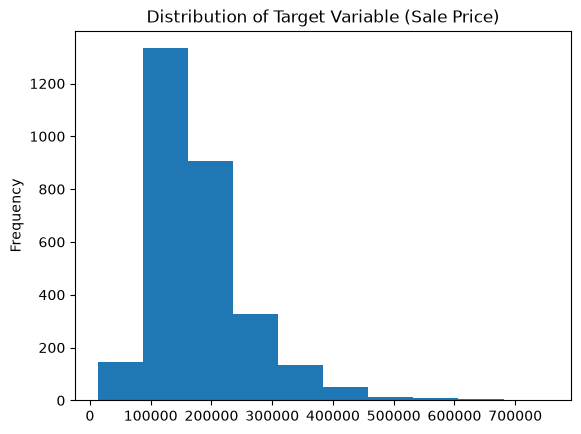

In [12]:
df['SalePrice'].plot.hist()
plt.title('Distribution of Target Variable (Sale Price)');

From the histogram, there is a concentration of prices is at the lower spectrum with a long tail at the higher prices. This indicates that the distribution is right-skewed.

In [13]:
df['SalePrice'].mean()

np.float64(180796.0600682594)

In [14]:
df['SalePrice'].median()

np.float64(160000.0)

In [15]:
df['SalePrice'].mode()

0    135000
Name: SalePrice, dtype: int64

In [22]:
df['SalePrice'].min()

np.int64(12789)

In [23]:
df['SalePrice'].max()

np.int64(755000)

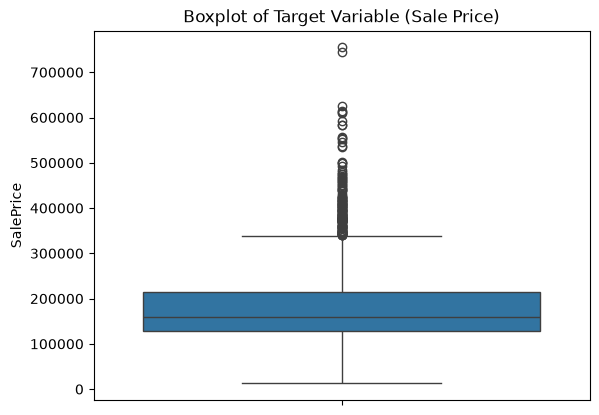

In [21]:
sns.boxplot(df['SalePrice'])
plt.title('Boxplot of Target Variable (Sale Price)');

From the boxplot, the middle 50% of data lie between 110000 and 210000. The upper limit is around 350000. The lower limit is around 10000. The are outliers that fall beyond the upper limit, with the most extreme falling beyond 700000. The median is close to the bottom showing that the data is right-skewed.

1. There are no missing values in the target variable
2. It is a numeric data type
3. The mean of the data is 180796.06
4. The median is data is 160000.0
5. The mode is 135000, with the modal class being 100000 to 200000
6. The max value is 755000
7. The min value is 12789

Effect of using a right-skewed distribution for predicting house prices
1. The mean becomes unreliable because is heavily pulled by the outliers
2. Loss functions like MSE or R2 become skewed
3. Residuals are right skewed which violated the assumption of Linear models.
4. Tree based models may waste splits trying to capture the extreme outliers

Probable solutions
1. Using loss functions less sensitive to outliers like MAE
2. Performing log transform of the target variable
3. Consider evaluating with metrics like RMSLE, MAE or MAPE